# Lab 5: Linear Regression
1. with plant species data
2. with fake data
------



Lab TA: Lee Ochs

In [2]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t
from scipy import stats

### Hypothesis: We have More Plant Species with Larger Island Area


Galapagos Islands are volcanic islands in the Eastern Pacific.\
Many Islands with different size and species abundance.

In [4]:
plant = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab5\Plant_Area.txt', sep=r'\s+')

#check the data

#practise
print(plant)

           Island    Area  Species
0       Albemarle  5824.9      325
1         Charles   165.8      319
2         Chatham   505.1      306
3           James   525.8      224
4   Indefatigable  1007.3      193
5        Abingdon    51.8      119
6          Duncan    18.4      103
7      Narborough   658.6       80
8            Hood    46.6       79
9         Seymour     2.6       52
10     Barrington    19.4       48
11        Gardner     0.5       48
12        Bindloe   116.6       47
13         Jervis     4.8       42
14          Tower    11.4       22
15         Wenman     4.7       14
16      Culpepper     2.3        7


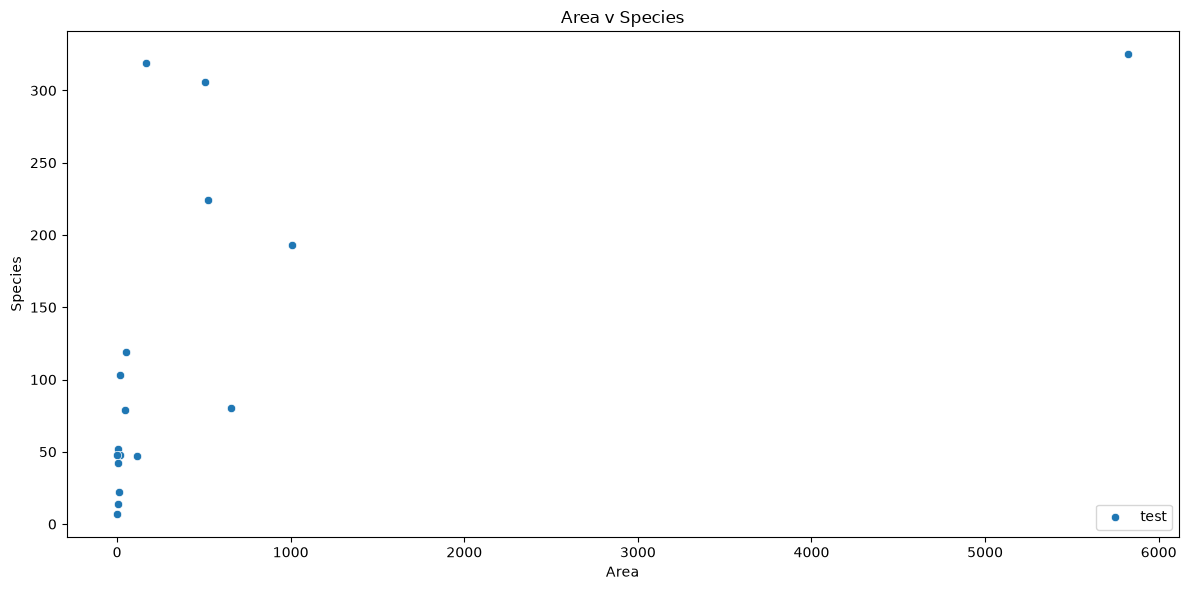

In [5]:

#examine the data by plotting a simple scatter plot between area vs species number 
#practise, plot the data species vs area
plt.figure(figsize=(12, 6))
sns.scatterplot(data= plant, x='Area', y='Species', label='test')
plt.xlabel('Area')
plt.ylabel('Species')
plt.title('Area v Species')

plt.tight_layout()
plt.show()


In [6]:
#we may need to log transform the data
# use the numpy log10 function, new data = np.log10(old data)
plant['log_Species'] = np.log10(plant['Species'])

#practise do the same for the area
plant['log_Area'] = np.log10(plant['Area'])

plant

#check the data

,Island,Area,Species,log_Species,log_Area
0,Albemarle,5824.9,325,2.511883,3.765288
1,Charles,165.8,319,2.503791,2.219585
2,Chatham,505.1,306,2.485721,2.703377
3,James,525.8,224,2.350248,2.720821
4,Indefatigable,1007.3,193,2.285557,3.003159
5,Abingdon,51.8,119,2.075547,1.714330
6,Duncan,18.4,103,2.012837,1.264818
7,Narborough,658.6,80,1.903090,2.818622
8,Hood,46.6,79,1.897627,1.668386
9,Seymour,2.6,52,1.716003,0.414973


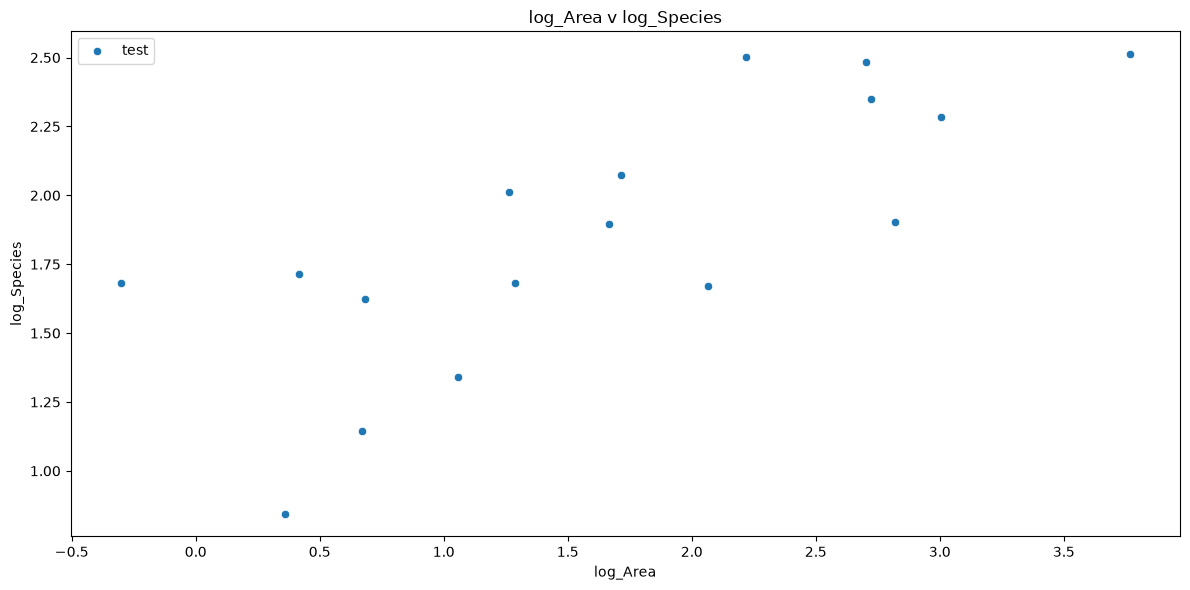

In [8]:
#practise
#plot again,
#but two scatter plots, log species vs area
#and log species vs log area
#tell me what you see
plt.figure(figsize=(12, 6))
sns.scatterplot(data= plant, x='log_Area', y='log_Species', label='test')
plt.xlabel('log_Area')
plt.ylabel('log_Species')
plt.title('log_Area v log_Species')

plt.tight_layout()
plt.show()

Linear Regression Model

Y = ax + b

Calculate the slope a, intercpet b, r value, p value, standard error.


In [10]:
#there is a simple function to get all the values using 
#stats.linregress(X, Y)
#this function return slope, intercept, r value, p value, standard error

from scipy import stats


#calculate the regression model 
test = stats.linregress(plant['log_Area'], plant['log_Species'])



In [24]:
# practise save the values into variables
# and print out the slope and r value

intercept = float(test.intercept)
slope = float(test.slope)
test

LinregressResult(slope=np.float64(0.32917225758140817), intercept=np.float64(1.322226751113036), rvalue=np.float64(0.7634495094184149), pvalue=np.float64(0.00036241206641133764), stderr=np.float64(0.07190195807021546), intercept_stderr=np.float64(0.1421630766836666))

Lets reconstruct the regression line (see class slide) \

1. plot the regression line Y_predict = intercept + slope * X and plot x vs y
2. Calculate the confidence interval (e.g., 95%)

<Axes: xlabel='log_Area', ylabel='log_Area'>

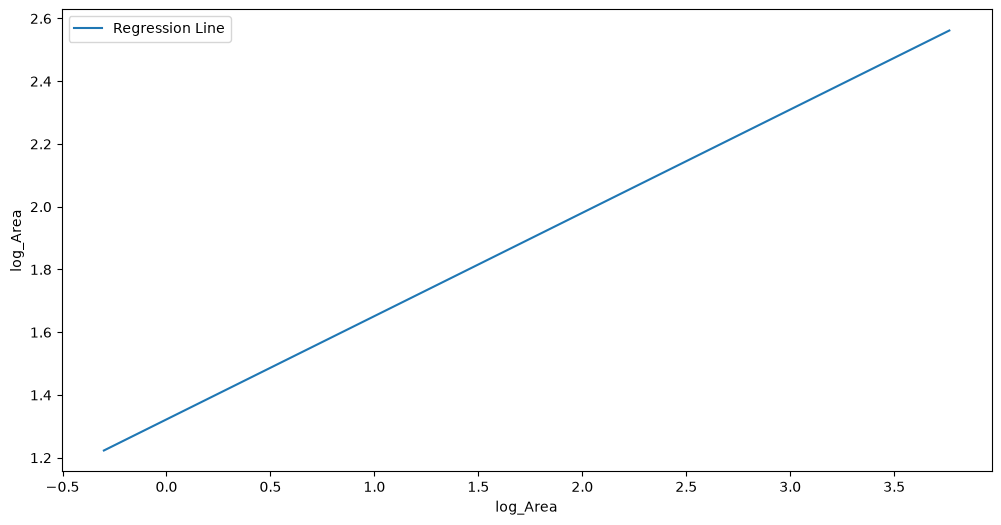

In [66]:
#constructing the regression line is pretty easy
#calcualte the predicted Y values using the regression line equation
#Y = ax + b

#practise: calculate the predicted y using the intercept and slope we got
#and plot
X = plant['log_Area']
Y_predict = intercept + slope * X

plt.figure(figsize=(12, 6))
sns.lineplot(x=X, y=Y_predict, label= 'Regression Line')


Confidence interval = Y_predict +- t_value * standard error of the fit of the point (see slides)
- It is different for each X.
- We know Y_predict, so we need to calcualte the t_value and the standard error
- t_value can be calculated using t = t(significance level, df) 
- we will use the t function from scipy t_value = t.ppf(1-α/2, degrees_of_freedom) 


- standard error of the fit:$$SE_{fit}(x_i) = s_e \sqrt{\frac{1}{n} + \frac{(x_i - \bar{x})^2}{S_{xx}}}$$


- we need to calculate the standard error of estimate: $$s_e = \sqrt{\frac{SSE}{n-2}}$$
- Sum of squared errors: $$SSE = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
- For the sum of squared deviations of X from its mean. $$S_{xx} = \sum_{i=1}^{n}(x_i - \bar{x})^2$$

In [67]:
#calculate t_value
#specify the confidence level, sample size n, degree of freedom,
confidence = 0.95
alpha = 1 - confidence
n= 14 #n is the number of data points
degrees_of_freedom = n-2 #n is the number of data points

t_value = t.ppf(1 - alpha/2, degrees_of_freedom)

In [68]:
#now calculate the standard error of the fit
# lets tackle the Se first 
# standard error:Se = sqrt(Σ(residuals²) / df_residual)
Y= plant['log_Species']

residuals = Y - Y_predict

#check residuals
print(residuals)

se=np.sqrt(np.sum(residuals**2)/degrees_of_freedom)
#check se
print(se)


0    -0.049772
1     0.450938
2     0.273618
3     0.132403
4    -0.025226
5     0.189010
6     0.274268
7    -0.346949
8     0.026214
9     0.257179
10   -0.064894
11    0.458105
12   -0.330429
13    0.076777
14   -0.327708
15   -0.397335
16   -0.596199
dtype: float64
0.35903527087315285


In [69]:
#now calculate 
X = plant['log_Area']
X_mean = np.mean(X)                    # Mean of X values
sxx = np.sum((X - X_mean)**2)  


In [70]:
#finally se_fit
se_fit = se * np.sqrt(1/n + (X - X_mean)**2 / sxx)

In [71]:
#set up confidence interval
upper = Y_predict + t_value * se_fit
lower = Y_predict - t_value * se_fit

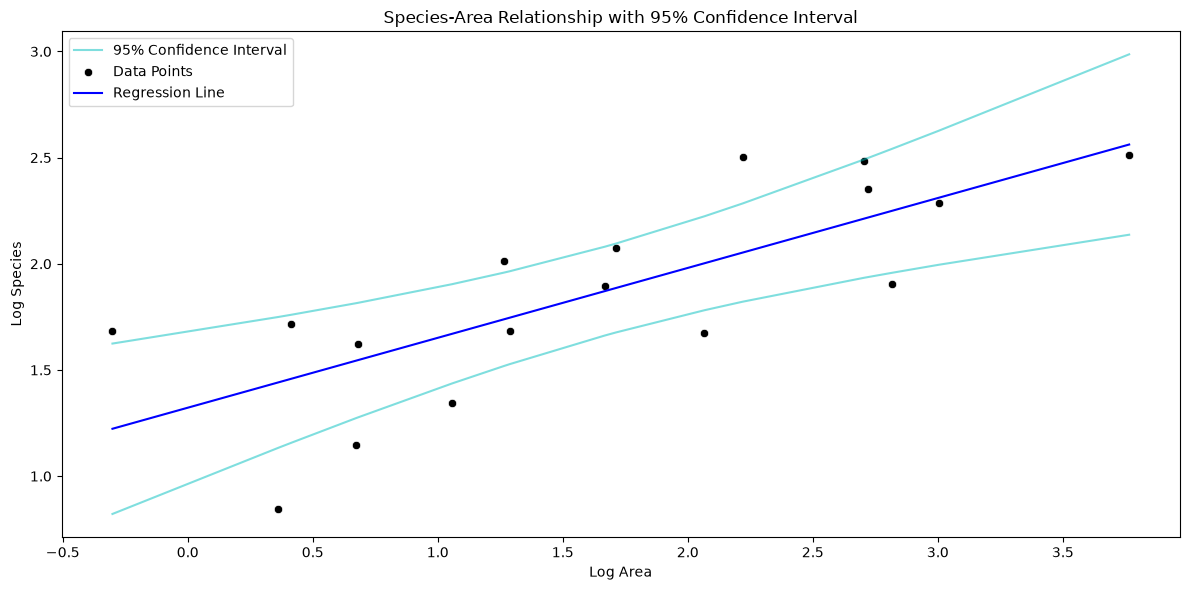

In [81]:
#plot
plt.figure(figsize=(12, 6))
# plt.fill_between(X, lower, upper, color='gray', alpha=0.5, label='95% Confidence Interval')
plt.plot(X.sort_values(), upper.sort_values(), color='c', alpha=0.5, label='95% Confidence Interval')
plt.plot(X.sort_values(), lower.sort_values(), color='c', alpha=0.5)
sns.scatterplot(data=plant, x='log_Area', y='log_Species', color = 'k', label= 'Data Points')
sns.lineplot(x=X, y=Y_predict, color='b', label= 'Regression Line')

plt.xlabel('Log Area')
plt.ylabel('Log Species')
plt.title('Species-Area Relationship with 95% Confidence Interval')
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\noahr\AppData\Local\Temp\ipykernel_68244\606152917.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


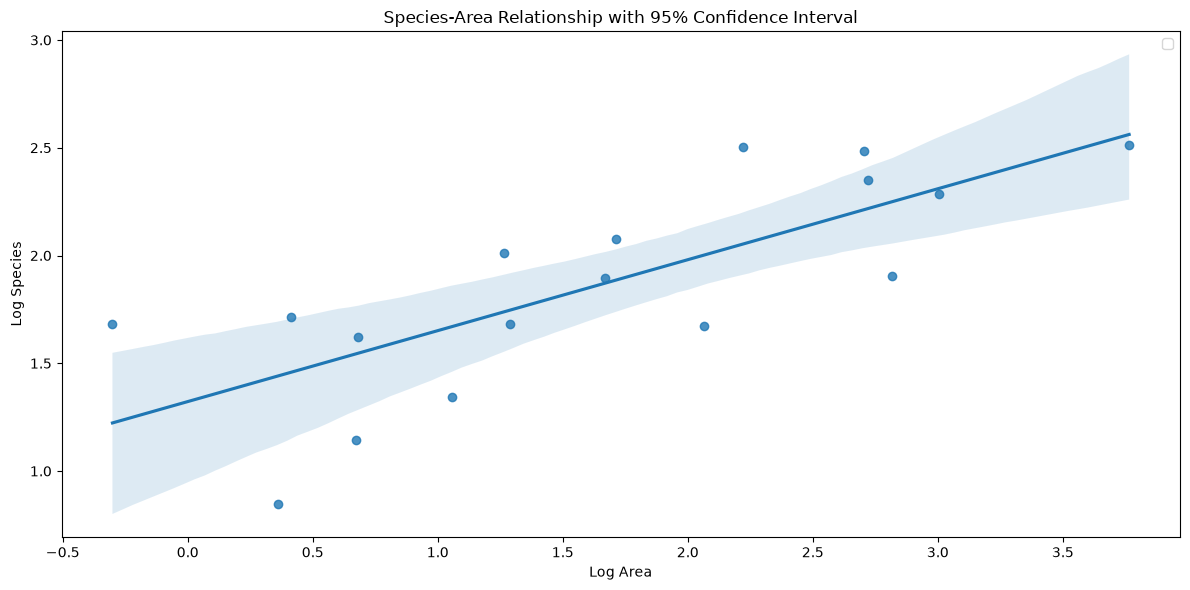

In [39]:

#there is easier ways to plot the confidence interval using sns pacakge
# --- IGNORE ---
plt.figure(figsize=(12, 6))
sns.regplot(data=plant, x='log_Area', y='log_Species', ci=95)
plt.xlabel('Log Area')
plt.ylabel('Log Species')
plt.title('Species-Area Relationship with 95% Confidence Interval')
plt.legend()
plt.tight_layout()
plt.show()

In reality, some data can be pretty messy/random/noisy\
How does the noise of data affect the regression performance?

In [82]:
#lets create some noisy data
#first, create a perfect linear relationship 
#for x, initiaze a range of values using np.linspace(a, b, n), a is start, b is end, n is number of points
#then create a linear relationship using y = cx + d, c is slope, d is intercept
x_perfect = np.linspace(0, 10, 10)
y_perfect = 2 * x_perfect + 3  # Perfect linear relationship


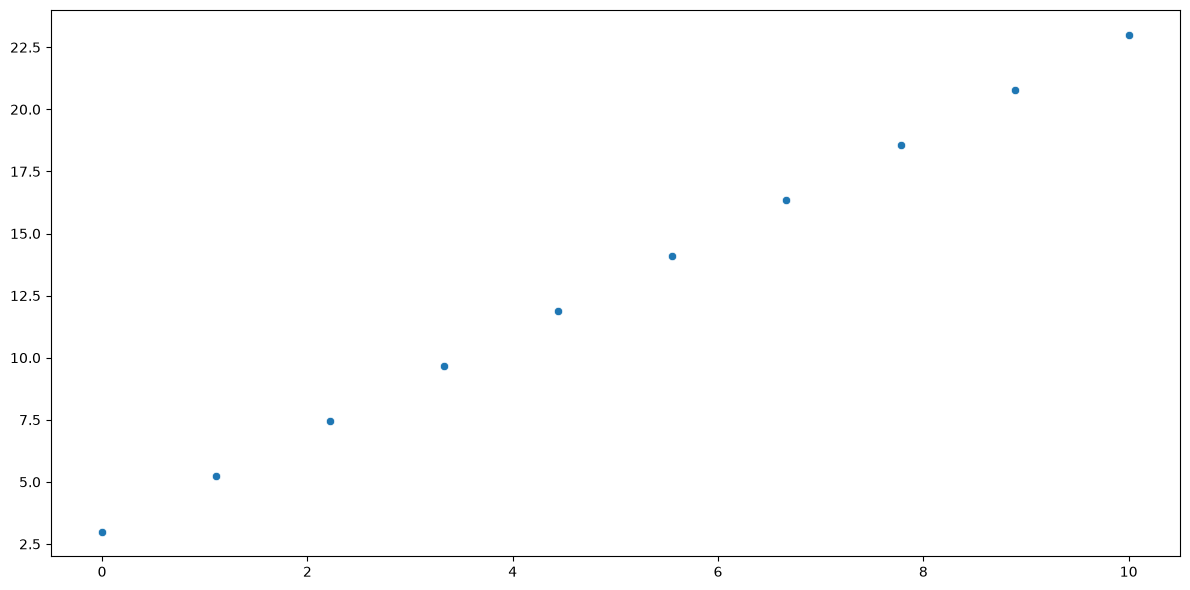

In [83]:
#examine the perfect data
plt.figure(figsize=(12, 6))
sns.scatterplot(x=x_perfect, y=y_perfect)
plt.tight_layout()
plt.show()

[0.75428655 0.60468891 0.91649756 0.67097139 0.94087074 0.51117425
 0.05904148 0.33847117 0.51508028 0.79151645]


<Axes: >

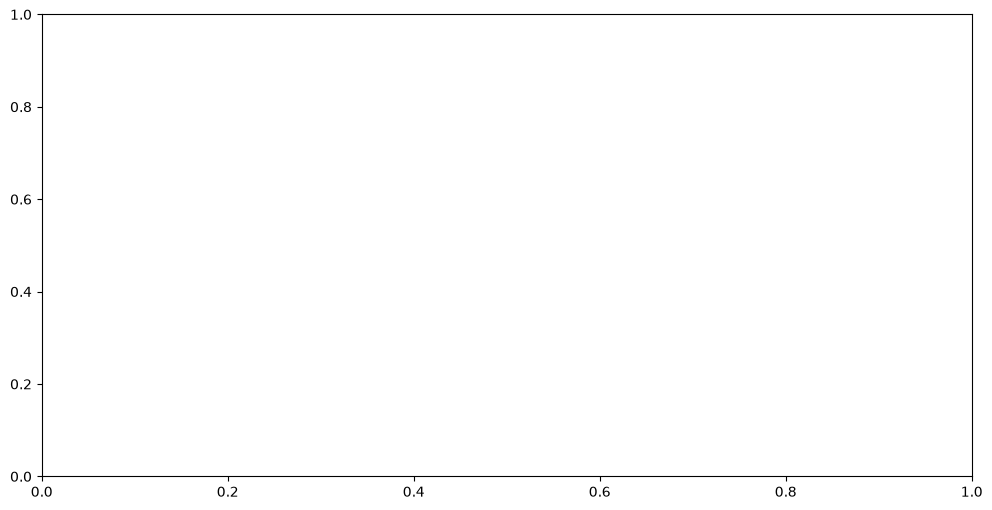

In [84]:
#now lets add some randomly generated number to every y values
#for example, lets create 10 random numbers between 0 and 1 using np.random.rand(10)
np.random.rand(10)

print(np.random.rand(10))

#add it to y_perfect
#y_noisy = y_perfect + np.random.rand(10)

#examine the noisy data
plt.figure(figsize=(12, 6))
sns.scatterplot()

#tell me what you see
#how about we add more noise by multiplying the random number by 10
#y_noisy2 = y_perfect + 10 * np.random.rand(10)
#plt.figure(figsize=(12, 6))
#sns.scatterplot(x=x_perfect, y=y_noisy2)



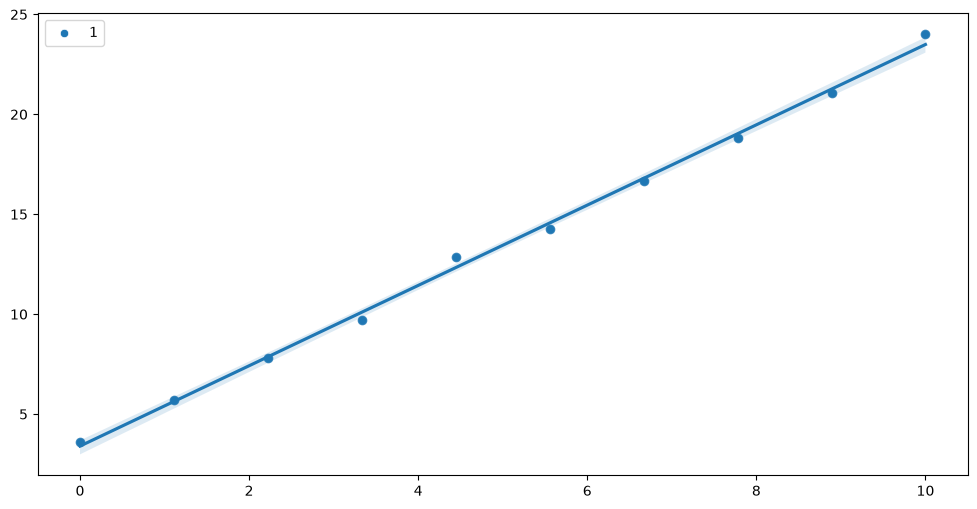

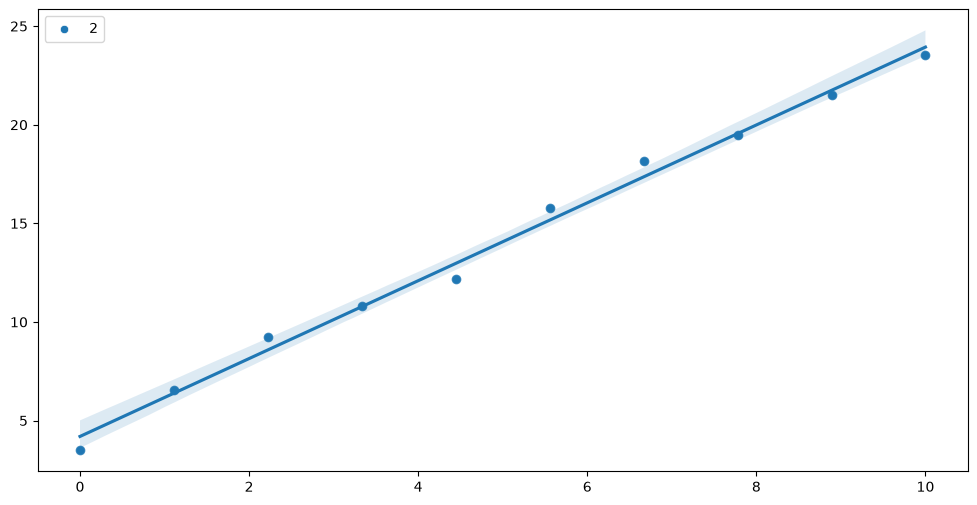

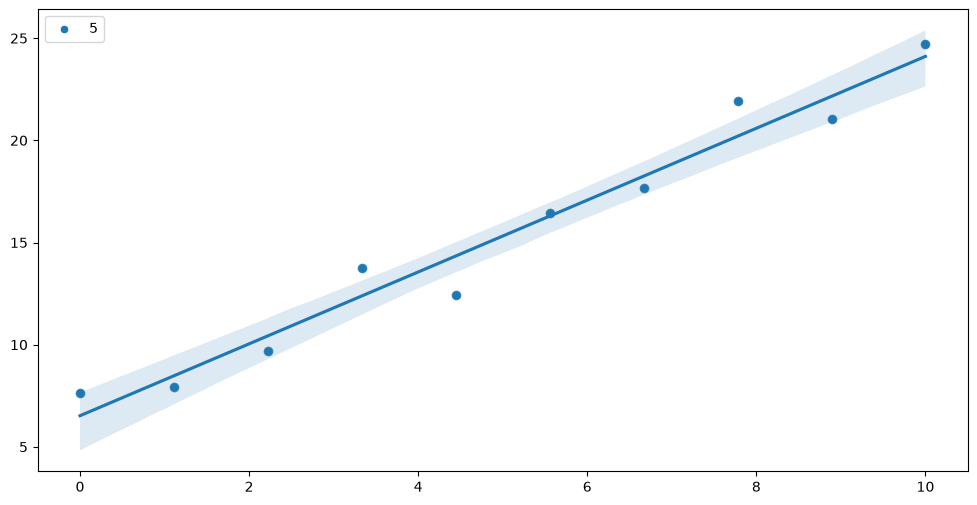

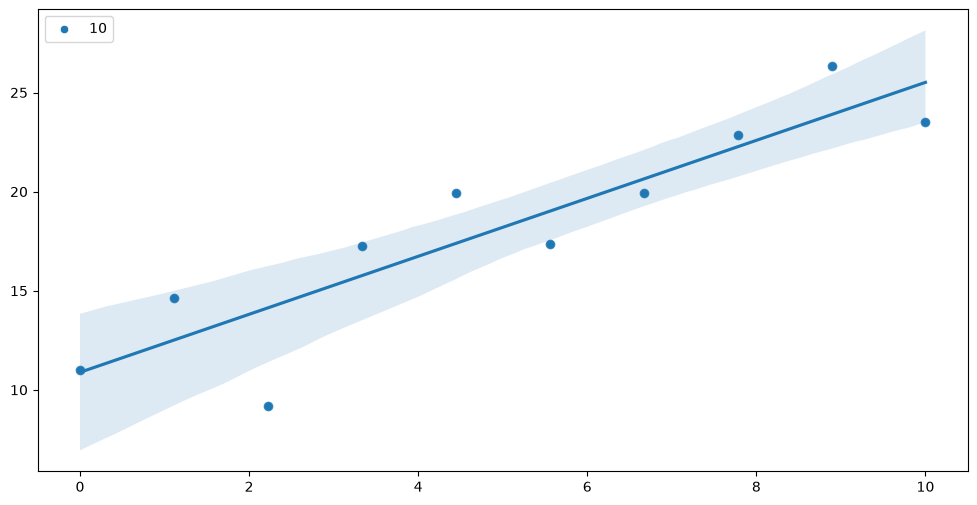

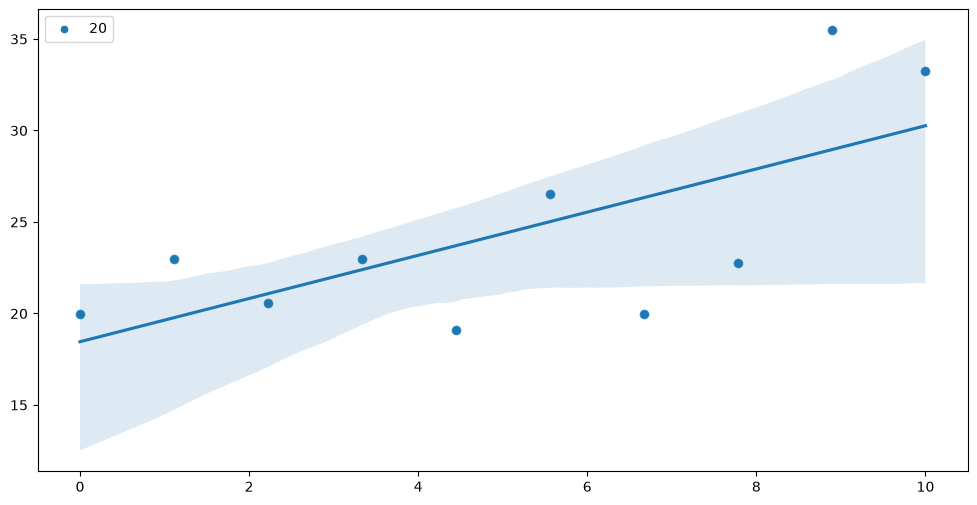

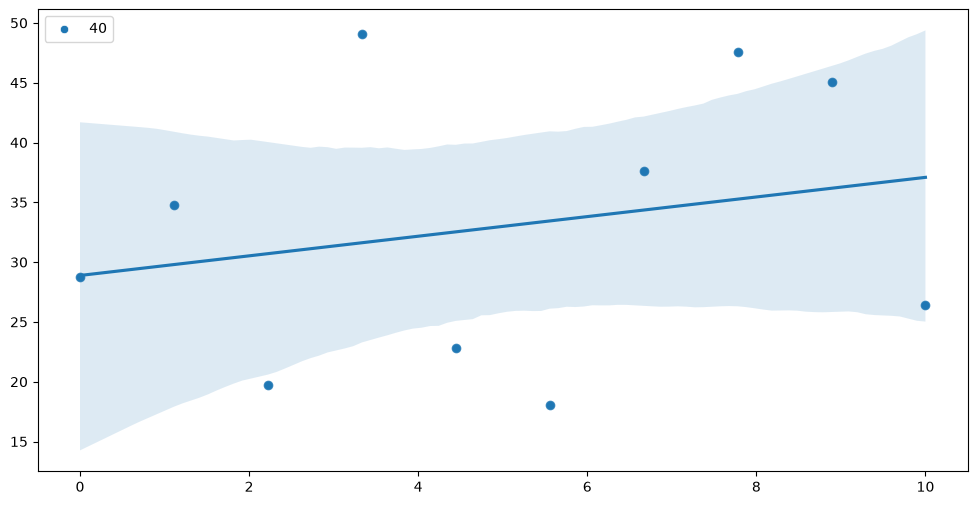

In [90]:
#lets compare the effect of differnet noise level on regression
#by multlipying the random number by differnet levels 1, 2, 5,10,20,40
factors_multiple = [1, 2, 5, 10, 20, 40]

#use a for loop through the list and plot


for factor in factors_multiple:
    y_noise = y_perfect + factor * np.random.rand(10)
    plt.figure(figsize=(12, 6))
    sns.scatterplot(x=x_perfect, y=y_noise, label = factor)
    sns.regplot(x=x_perfect, y=y_noise, ci=95)
    

In [ ]:
#what about the p values and r number
#use the same function to get r and p for each factor and plot factor vs r and p
#slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)

In [ ]:
#practise
r_values = []
p_values = []

for factor in factors_multiple:
    y_noise = y_perfect + 
    #slope, intercept, r_value, p_value, std_err = stats.linregress(x_perfect, y_noise)
    #use the append funciton to append p and r
    
   

    

In [91]:
#practise 
#use sns.scatterplot to plot the p values and r values vs factors, on the same plot, label them accordingly
sns.scatterplot(x=factors_multiple, y= p_values)
sns.scatterplot(x=factors_multiple, y= r_values)

NameError: name 'p_values' is not defined